# Tree Ensembles: Random Forests & Boosting

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/konstantin-schekotihin/dl_course/blob/master/AI-ML/05_ensembles.ipynb)


In [1]:
# Setup & configuration (skip in presentation slides)
%matplotlib inline
from IPython.display import Markdown, display
import os
import numpy as np
import pandas as pd
import wandb
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text
import sklearn.metrics as mt

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import aiml as hp
hp.setup_theme()

## 1. Decision Trees: The Tabular Baseline & Overfitting

- A decision tree splits the feature space into boxes and predicts the same value for all observations in a box: the mean target (regression) or the most frequent class (classification).
- **Single trees**
  - ➕ easy to explain and to draw, close to human decision making
  - ➕ handle qualitative features and unscaled features (invariant to monotonic rescaling)
  - ➖ usually less accurate than the best other methods
  - ➖ **non-robust**: a small change of the data can produce a very different tree
- **Ensembles of trees** (bagging, random forests, boosting) fix the accuracy problem, at the price of interpretability. On structured, tabular data (economics, healthcare, marketing, finance) they are a strong default.

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 8: Tree-Based Methods. Springer](https://doi.org/10.1007/978-3-031-38747-0_8)*</small>

### A Regression Tree: Baseball Salaries

- **Hitters** data (Lecture 02): predict the log-salary of a player from *Years* (in the major leagues) and *Hits* (in the last season).
- The tree is grown by **recursive binary splitting**: top-down and greedy, each split chooses the feature and the cut point that reduce the $\mathrm{RSS}$ most.
- Each leaf predicts the mean log-salary of its training players.

In [2]:
hitters = pd.read_csv(hp.get_data_path("Hitters.csv")).dropna()
log_salary = np.log(hitters.Salary)                       # salaries are skewed; ISLP models the log-salary

salary_tree = DecisionTreeRegressor(max_leaf_nodes=3, random_state=0).fit(hitters[["Years", "Hits"]], log_salary)
print(export_text(salary_tree, feature_names=["Years", "Hits"], decimals=2))
for leaf_value in np.unique(salary_tree.predict(hitters[["Years", "Hits"]])):
    display(Markdown(rf"leaf mean log-salary ${leaf_value:.2f}$ $\Rightarrow$ salary $e^{{{leaf_value:.2f}}} \times \$1000 = \${1000 * np.exp(leaf_value):,.0f}$"))

|--- Years <= 4.50
|   |--- value: [5.11]
|--- Years >  4.50
|   |--- Hits <= 117.50
|   |   |--- value: [6.00]
|   |--- Hits >  117.50
|   |   |--- value: [6.74]



leaf mean log-salary $5.11$ $\Rightarrow$ salary $e^{5.11} \times \$1000 = \$165,139$

leaf mean log-salary $6.00$ $\Rightarrow$ salary $e^{6.00} \times \$1000 = \$402,776$

leaf mean log-salary $6.74$ $\Rightarrow$ salary $e^{6.74} \times \$1000 = \$845,296$

### Decision Tree Induction & Splitting Criteria

- *Recap of Introduction to AI 2*: recursive binary splitting partitions the feature space into axis-aligned boxes, top-down and greedy.
- At an internal node with sample index set $\mathcal{S}$, the algorithm searches over features $i \in \{1, \dots, D\}$ and thresholds $\theta$ for the largest **impurity decrease**:

$$
\Delta(\mathcal{S}, i, \theta) = I(\mathcal{S}) - \frac{|\mathcal{S}_L|}{|\mathcal{S}|} I(\mathcal{S}_L) - \frac{|\mathcal{S}_R|}{|\mathcal{S}|} I(\mathcal{S}_R)
$$

  where $\mathcal{S}_L = \{n \in \mathcal{S} \mid x_{ni} \le \theta\}$ and $\mathcal{S}_R = \{n \in \mathcal{S} \mid x_{ni} > \theta\}$ are the partitioned subsets.
- Regression trees use the $\mathrm{RSS}$ of the node as impurity. For classification, with class proportions $p_k = \frac{1}{|\mathcal{S}|}\sum_{n \in \mathcal{S}} \mathbb{I}(t_n = \mathcal{C}_k)$ ($k = 1, \dots, K$):
  - **Entropy**: $H(\mathcal{S}) = -\sum_{k=1}^K p_k \log_2 p_k$
  - **Gini Impurity**: $I_G(\mathcal{S}) = 1 - \sum_{k=1}^K p_k^2$
  - **Classification Error**: $I_E(\mathcal{S}) = 1 - \max_k p_k$
- Grow the tree with Gini or entropy (scikit-learn default: Gini): the classification error is not sensitive enough. For pruning, the classification error is a natural choice when accuracy is the goal.

In [3]:
def gini(p):
    """Gini impurity 1 - sum_k p_k^2 of class proportions p."""
    return 1 - np.sum(np.square(p))

def entropy(p):
    """Entropy -sum_k p_k log2 p_k (terms with p_k = 0 contribute 0)."""
    p = np.asarray(p, dtype=float)
    return -np.sum(p[p > 0] * np.log2(p[p > 0]))

def class_error(p):
    """Classification error 1 - max_k p_k."""
    return 1 - np.max(p)

# A split of 20 observations (16 "Yes"): left 11 observations (7 "Yes"), right 9 observations (all "Yes")
for impurity in (class_error, gini, entropy):
    before = impurity([16 / 20, 4 / 20])
    after = 11 / 20 * impurity([7 / 11, 4 / 11]) + 9 / 20 * impurity([9 / 9, 0])
    display(Markdown(f"{impurity.__name__}: {before:.3f} before, {after:.3f} after the split (decrease {np.round(before - after, 3) + 0.0:.3f})"))

class_error: 0.200 before, 0.200 after the split (decrease 0.000)

gini: 0.320 before, 0.255 after the split (decrease 0.065)

entropy: 0.722 before, 0.520 after the split (decrease 0.202)

### The Overfitting Dilemma of Single Decision Trees

- An unconstrained decision tree grows until every single leaf is completely pure ($I(\mathcal{S}) = 0$):
  - **Training Error**: Drops to $0\%$ (**low bias**).
  - **Generalization**: Severely degrades on test data (**high variance**).
- Single trees produce jagged, fragmented step boundaries that memorize idiosyncratic noise.
- **Controlling Tree Capacity**:
  - **Pre-pruning (Early Stopping)**: Restrict `max_depth`, require `min_samples_split`, or set `min_samples_leaf`. Short-sighted: a weak split can be followed by a very good one.
  - **Post-pruning (Cost-Complexity)**: Minimize penalized loss $R_\alpha(\mathcal{T}) = R(\mathcal{T}) + \alpha |\mathcal{T}|$, balancing empirical error $R(\mathcal{T})$ against tree complexity $|\mathcal{T}|$ (number of leaves). Grow a large tree first, then prune it back; choose $\alpha$ by cross-validation.

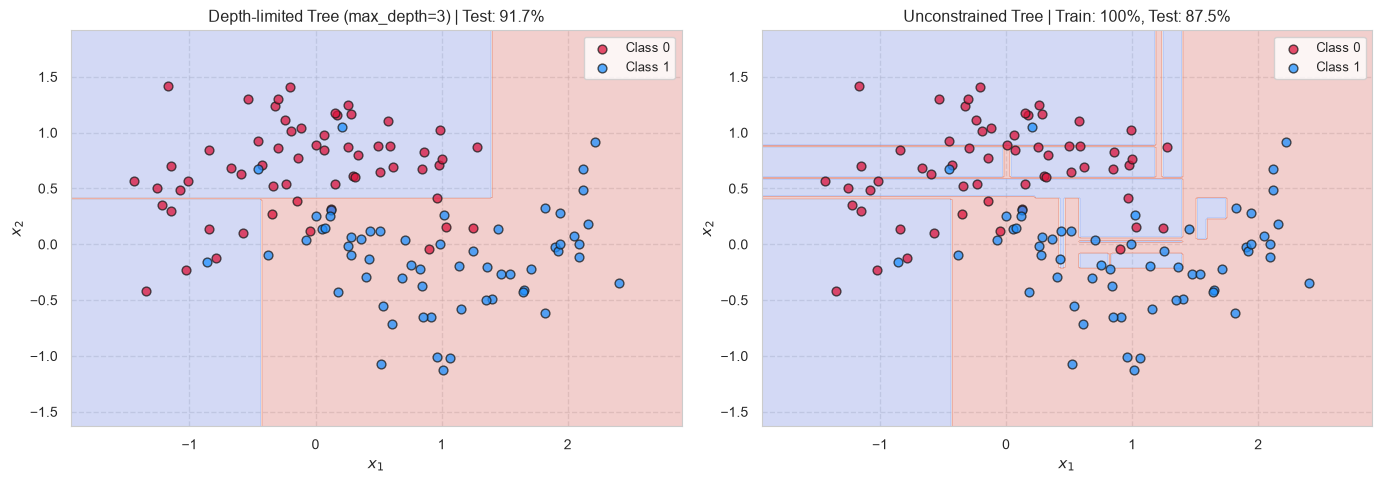

In [4]:
# Generate noisy non-linear two moons dataset
X, y = make_moons(n_samples=400, noise=0.30, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Fit constrained vs. unconstrained single decision trees
tree_shallow = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr, y_tr)
tree_deep = DecisionTreeClassifier(max_depth=None, random_state=42).fit(X_tr, y_tr)

acc_shallow_te = tree_shallow.score(X_te, y_te)
acc_deep_tr = tree_deep.score(X_tr, y_tr)
acc_deep_te = tree_deep.score(X_te, y_te)

hp.plot_decision_boundaries_comparison({
    f"Depth-limited Tree (max_depth=3) | Test: {acc_shallow_te:.1%}": tree_shallow,
    f"Unconstrained Tree | Train: {acc_deep_tr:.0%}, Test: {acc_deep_te:.1%}": tree_deep,
}, X_te, y_te)

### Cost-Complexity Pruning

- Grow a deep tree $\mathcal{T}_0$. For each $\alpha \ge 0$ there is a subtree $\mathcal{T} \subseteq \mathcal{T}_0$ minimizing $R(\mathcal{T}) + \alpha |\mathcal{T}|$; as $\alpha$ grows, the subtrees get smaller and are nested.
- Choose $\alpha$ by $S$-fold cross-validation on the training data, then evaluate the pruned tree once on the test data.

In [5]:
pruning_path = tree_deep.cost_complexity_pruning_path(X_tr, y_tr)       # the alphas at which the subtree changes
pruning_search = GridSearchCV(DecisionTreeClassifier(random_state=42), {"ccp_alpha": pruning_path.ccp_alphas[:-1]},
                              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
pruning_search.fit(X_tr, y_tr)
tree_pruned = pruning_search.best_estimator_
display(Markdown(rf"CV chooses $\alpha = {pruning_search.best_params_['ccp_alpha']:.4f}$: leaves {tree_deep.get_n_leaves()} $\to$ {tree_pruned.get_n_leaves()}; "
                 f"test accuracy {tree_deep.score(X_te, y_te):.3f} (deep) vs. {tree_pruned.score(X_te, y_te):.3f} (pruned)"))

CV chooses $\alpha = 0.0108$: leaves 33 $\to$ 7; test accuracy 0.875 (deep) vs. 0.883 (pruned)

### Trees vs. Linear Models

- A linear model is best when the true class boundary is (close to) a straight line; a tree needs a staircase of axis-aligned splits to approximate it.
- A tree is best when the boundary consists of axis-aligned pieces, which a linear model cannot follow.
- Example: uniform points in $[-2, 2]^2$, $5\%$ of the labels flipped; class $1$ if $x_1 + x_2 > 0$ (diagonal) or if $x_1 > 0$ and $x_2 > 0$ (box). Tree depth chosen by CV.

In [6]:
rng = np.random.default_rng(0)
X_sim = rng.uniform(-2, 2, size=(400, 2))
boundaries = {"diagonal": X_sim[:, 0] + X_sim[:, 1] > 0, "box": (X_sim[:, 0] > 0) & (X_sim[:, 1] > 0)}
for name, true_class in boundaries.items():
    t_sim = np.where(rng.random(400) < 0.05, ~true_class, true_class).astype(int)      # 5 % label noise
    Xs_tr, Xs_te, ts_tr, ts_te = train_test_split(X_sim, t_sim, test_size=0.5, random_state=0, stratify=t_sim)
    linear = LogisticRegression().fit(Xs_tr, ts_tr)
    tree = GridSearchCV(DecisionTreeClassifier(random_state=0), {"max_depth": [1, 2, 3, 4, 6, 8]},
                        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0)).fit(Xs_tr, ts_tr)
    display(Markdown(f"{name} boundary: test accuracy logistic regression {linear.score(Xs_te, ts_te):.3f}, tree {tree.score(Xs_te, ts_te):.3f}"))

diagonal boundary: test accuracy logistic regression 0.915, tree 0.840

box boundary: test accuracy logistic regression 0.815, tree 0.915

## 2. Ensemble Foundations: Bagging & Bootstrap Aggregation

- **Condorcet's Jury Theorem (1785)**: If $B$ independent voters each have probability $p > 0.5$ of reaching a correct verdict, the probability that the majority vote is correct approaches $1.0$ as $B \to \infty$!
- In Machine Learning, an **ensemble** aggregates predictions from $B$ diverse base estimators:

$$
y_{\mathrm{ens}}(\mathbf{x}) = \mathrm{mode}\left( \{ y_b(\mathbf{x}) \}_{b=1}^B \right) \quad (\text{classification}), \qquad y_{\mathrm{ens}}(\mathbf{x}) = \frac{1}{B} \sum_{b=1}^B y_b(\mathbf{x}) \quad (\text{regression})
$$

  (scikit-learn's random forest averages the trees' predicted class probabilities instead; for fully grown trees this gives the same as the majority vote.)
- **Two Fundamental Ensemble Paradigms**:
  1. **Bagging (Bootstrap Aggregation)**: Trains diverse high-variance models in **parallel** on randomized data subsets $\implies$ **slashes variance**.
  2. **Boosting**: Trains shallow high-bias models in **series**, where each tree learns to predict the residual errors of prior trees $\implies$ **slashes bias**.

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 8: Tree-Based Methods. Springer](https://doi.org/10.1007/978-3-031-38747-0_8)*</small>

### Bootstrap Aggregation: Bagging

- How do we obtain $B$ distinct training sets from a single empirical sample $\mathcal{D}$ of size $N$?
- **The Non-Parametric Bootstrap (Efron 1979)**: Sample $N$ instances *uniformly at random with replacement* from $\mathcal{D}$.
- What fraction of original observations are omitted from a bootstrap replicate?

$$
P(\text{sample } n \text{ omitted in } N \text{ draws}) = \left(1 - \frac{1}{N}\right)^N \xrightarrow{N \to \infty} \frac{1}{e} \approx 36.8\%
$$

- Each bootstrap dataset contains approximately **$63.2\%$ unique observations**.
- The remaining **$36.8\%$ unused observations** are called **Out-of-Bag (OOB)** samples!


In [7]:
# One bootstrap sample of the two-moons training set
N = len(X_tr)
bootstrap_index = np.random.default_rng(0).choice(N, size=N, replace=True)       # N draws with replacement
display(Markdown(rf"Unique observations in this bootstrap sample: {len(np.unique(bootstrap_index)) / N:.3f}; "
                 rf"expected $1 - (1 - 1/N)^N = {1 - (1 - 1 / N) ** N:.3f}$ for $N = {N}$"))

Unique observations in this bootstrap sample: 0.614; expected $1 - (1 - 1/N)^N = 0.633$ for $N = 280$

### Why Average Many Trees? Trees Are Non-Robust

- Grow the same small tree (depth $2$) on two random halves of the Hitters players: the splits differ.
- A single tree has a high **variance**; averaging many trees grown on different bootstrap samples reduces it.

In [8]:
features = ["Years", "Hits", "Walks", "RBI", "PutOuts"]
for seed in (0, 1):
    half = hitters.sample(frac=0.5, random_state=seed)
    half_tree = DecisionTreeRegressor(max_depth=2, random_state=0).fit(half[features], np.log(half.Salary))
    print(f"Random half {seed + 1}:")
    print(export_text(half_tree, feature_names=features, decimals=1))

Random half 1:
|--- Years <= 3.5
|   |--- Hits <= 20.5
|   |   |--- value: [6.8]
|   |--- Hits >  20.5
|   |   |--- value: [4.7]
|--- Years >  3.5
|   |--- Walks <= 51.5
|   |   |--- value: [6.0]
|   |--- Walks >  51.5
|   |   |--- value: [6.8]

Random half 2:
|--- Years <= 4.5
|   |--- Years <= 3.5
|   |   |--- value: [4.9]
|   |--- Years >  3.5
|   |   |--- value: [5.6]
|--- Years >  4.5
|   |--- Hits <= 118.0
|   |   |--- value: [6.0]
|   |--- Hits >  118.0
|   |   |--- value: [6.7]



## 3. Random Forests: Decorrelating Decision Trees

- **Leo Breiman (2001)** identified a fundamental limitation of naive tree bagging:
  - If a few features are strong predictors, almost every bootstrap tree splits on those same dominant features near the root.
  - Consequently, individual tree predictions become **strongly correlated** ($\rho > 0$).
  - For $B$ estimators with variance $\sigma^2$ and pairwise correlation $\rho$, the variance of their average is:

$$
\mathrm{var}\left( \frac{1}{B} \sum_{b=1}^B y_b \right) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2 \xrightarrow{B \to \infty} \rho \sigma^2
$$

- **The Random Forest Solution (Feature Subsampling)**:
  - At *every candidate split*, sample only $m < D$ features at random (default $m = \lfloor \sqrt{D} \rfloor$).
  - Forces trees to explore diverse feature combinations, which lowers $\rho$ and therefore the variance of the average.
  - With $m = D$ a random forest is plain bagging.

### Out-of-Bag (OOB) Evaluation & Feature Importance

- **Free Cross-Validation via Out-of-Bag (OOB) Score**:
  - For observation $(\mathbf{x}_n, t_n)$, predict using only the subset of trees (${\approx} B/3$) where $\mathbf{x}_n$ was omitted.
  - Aggregating OOB predictions gives a valid estimate of the test error **without a holdout validation set**; with many trees it is close to leave-one-out cross-validation.
  - More trees never make bagging or a random forest overfit; the error just levels off.
- **Mean Decrease in Impurity (MDI) Feature Importance**:
  - Quantifies how much feature $i$ contributes to reducing node impurity across all splits in all $B$ trees:

$$
\mathrm{MDI}(i) = \frac{1}{B} \sum_{b=1}^B \sum_{\tau \in \mathcal{T}_b : v(\tau) = i} \frac{N_\tau}{N} \Delta I(\tau)
$$

  where node $\tau$ of tree $\mathcal{T}_b$ splits on feature $v(\tau)$, holds $N_\tau$ samples and reduces impurity by $\Delta I(\tau)$.
- Automatically ranks the explanatory power of each predictor in the dataset.

Random Forest Out-of-Bag (OOB) Accuracy : 87.1%
Random Forest Independent Test Accuracy  : 89.2%


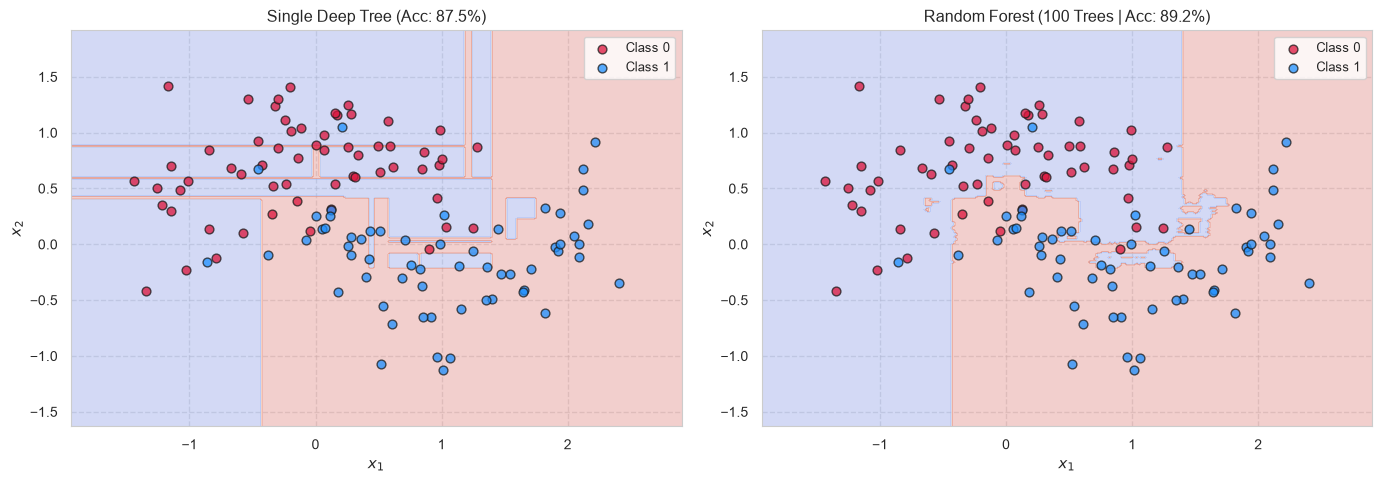

In [9]:
# Train Random Forest with Out-of-Bag scoring
rf = RandomForestClassifier(n_estimators=100, max_features='sqrt', oob_score=True, random_state=42)
rf.fit(X_tr, y_tr)

acc_rf_te = rf.score(X_te, y_te)
print(f"Random Forest Out-of-Bag (OOB) Accuracy : {rf.oob_score_:.1%}")
print(f"Random Forest Independent Test Accuracy  : {acc_rf_te:.1%}")

hp.plot_decision_boundaries_comparison({
    f"Single Deep Tree (Acc: {acc_deep_te:.1%})": tree_deep,
    f"Random Forest (100 Trees | Acc: {acc_rf_te:.1%})": rf,
}, X_te, y_te)

## 4. Boosting: The Sequential Correction Paradigm

- While Random Forests build independent trees in parallel, **Boosting** builds trees **sequentially in series**.
- Each new tree is specifically trained to correct the errors made by all previous trees combined:

$$
F_M(\mathbf{x}) = F_0(\mathbf{x}) + \sum_{m=1}^M \eta h_m(\mathbf{x})
$$

- **Three tuning parameters**:
  - **Number of trees $M$**: unlike bagging, boosting can overfit if $M$ is too large; choose $M$ by cross-validation.
  - **Shrinkage $\eta \in (0, 1]$** (learning rate): scales the contribution of each tree; small values (e.g. $0.01$–$0.1$) learn slowly and need a larger $M$.
  - **Tree size $d$**: the number of splits per tree. Often $d = 1$ (stumps) works well; `max_depth=1` gives a stump, `max_depth=3` up to $7$ splits.
- Two fundamental milestones in boosting literature:
  1. **AdaBoost** (Freund & Schapire 1997): Reweights misclassified instances exponentially.
  2. **Gradient Boosting (GBM)** (Friedman 2001): Performs functional gradient descent on arbitrary loss functions.

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 8: Tree-Based Methods. Springer](https://doi.org/10.1007/978-3-031-38747-0_8)*</small>

### Boosting Regression Trees: Fitting the Residuals

1. Set $F_0(\mathbf{x}) = 0$ and the residuals $r_n = t_n$ for all training observations.
2. For $m = 1, \dots, M$:
   - fit a small tree $h_m$ (with $d$ splits) to the data $(\mathbf{x}_n, r_n)$,
   - add a shrunken version to the model: $F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \eta\, h_m(\mathbf{x})$,
   - update the residuals: $r_n \leftarrow r_n - \eta\, h_m(\mathbf{x}_n)$.
3. Output the boosted model $F_M(\mathbf{x})$.

- Each tree learns slowly from what the previous trees left unexplained. Below: Hitters log-salaries, stumps, $\eta = 0.1$.

In [10]:
X_hit = hitters[features].to_numpy()
t_hit = log_salary.to_numpy()
eta, M = 0.1, 100

F = np.zeros(len(t_hit))                # F_0 = 0
r = t_hit.copy()                        # residuals start as the targets
for m in range(1, M + 1):
    stump = DecisionTreeRegressor(max_depth=1).fit(X_hit, r)
    step = eta * stump.predict(X_hit)
    F, r = F + step, r - step
    if m <= 3:
        display(Markdown(rf"round {m}: $\mathrm{{RSS}} = {np.sum(r ** 2):.2f}$"))

sklearn_boost = GradientBoostingRegressor(init="zero", max_depth=1, learning_rate=eta, n_estimators=M).fit(X_hit, t_hit)
display(Markdown(f"Largest difference to `GradientBoostingRegressor` after {M} rounds: {np.abs(sklearn_boost.predict(X_hit) - F).max():.1e}"))

round 1: $\mathrm{RSS} = 7673.82$

round 2: $\mathrm{RSS} = 6237.65$

round 3: $\mathrm{RSS} = 5073.92$

Largest difference to `GradientBoostingRegressor` after 100 rounds: 3.6e-15

### Gradient Boosted Decision Trees

- Consider empirical risk minimization for differentiable loss $L(t, F(\mathbf{x}))$:

$$
\min_F \sum_{n=1}^N L(t_n, F(\mathbf{x}_n))
$$

- At stage $m$, we compute the **pseudo-residuals** (the negative gradient of loss with respect to current predictions):

$$
r_{nm} = - \left[ \frac{\partial L(t_n, F(\mathbf{x}_n))}{\partial F(\mathbf{x}_n)} \right]_{F(\mathbf{x}) = F_{m-1}(\mathbf{x})}
$$

- A shallow regression tree $h_m(\mathbf{x})$ is fit to targets $r_{nm}$ using squared error.
- For the squared error $L = \frac{1}{2}(t_n - F(\mathbf{x}_n))^2$, the pseudo-residual is just the residual $t_n - F_{m-1}(\mathbf{x}_n)$: the algorithm of the previous slide. Other losses (e.g. for classification) replace it by the negative gradient.
- Update model: $F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \eta h_m(\mathbf{x})$.
> 💡 **Intuition:** Successive trees step in the direction of steepest descent in function space!

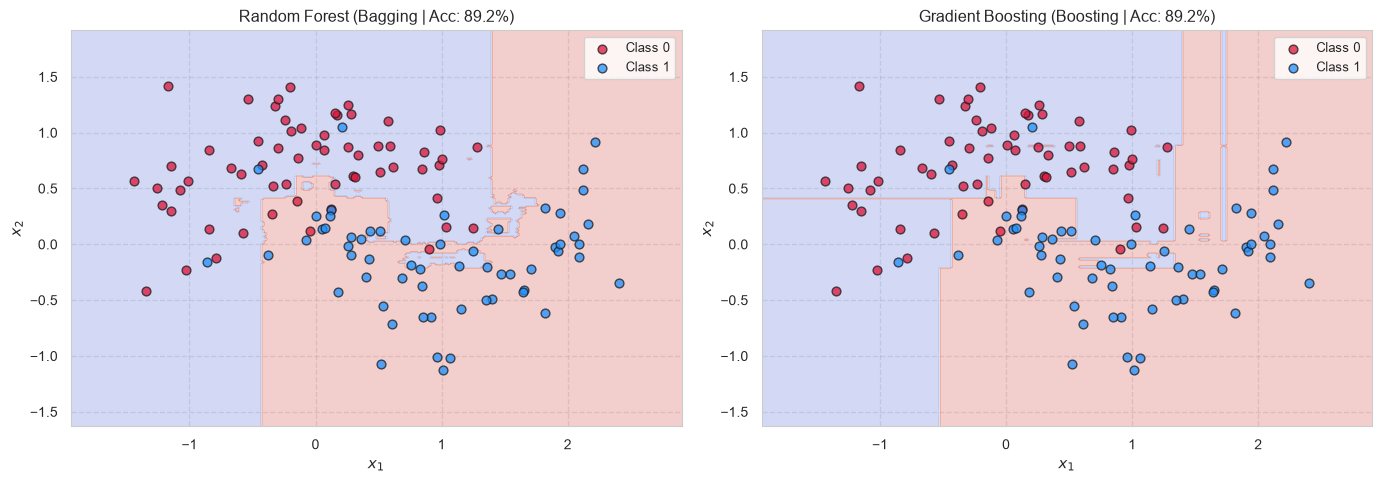

In [11]:
# Train Gradient Boosting Classifier
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_tr, y_tr)
acc_gb_te = gb.score(X_te, y_te)

hp.plot_decision_boundaries_comparison({
    f"Random Forest (Bagging | Acc: {acc_rf_te:.1%})": rf,
    f"Gradient Boosting (Boosting | Acc: {acc_gb_te:.1%})": gb,
}, X_te, y_te)

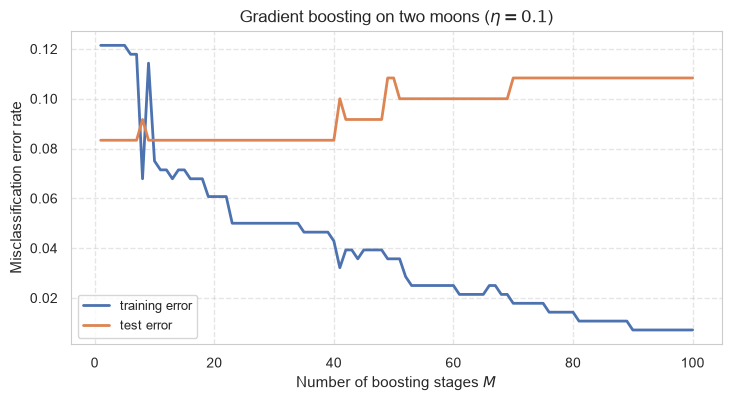

In [12]:
# Error after each boosting stage (illustration only: M itself is chosen by CV in §5, never on the test set)
train_errors_gb = [mt.zero_one_loss(y_tr, y_pred) for y_pred in gb.staged_predict(X_tr)]
test_errors_gb = [mt.zero_one_loss(y_te, y_pred) for y_pred in gb.staged_predict(X_te)]
hp.plot_curves(np.arange(1, gb.n_estimators + 1), {"training error": train_errors_gb, "test error": test_errors_gb},
               xlabel="Number of boosting stages $M$", ylabel="Misclassification error rate",
               title=r"Gradient boosting on two moons ($\eta = 0.1$)")

## 5. Applied Case Study: Breast Cancer Diagnostic Benchmark

- **Dataset**: Wisconsin Diagnostic Breast Cancer dataset (569 patients, $D=30$ continuous nuclear features).
- **Task $(T, P, E)$**:
  - $T$: Predict whether a biopsied tissue mass is benign ($0$) or malignant ($1$, the positive class).
  - $P$: Accuracy, $F_1$-score of the malignant class and ROC-AUC on a held-out test set; hyperparameters chosen by cross-validation on the training set.
  - $E$: 569 digitized cell nuclei measurement vectors.
- We compare a baseline and four tree-based models:
  1. **Majority class** baseline
  2. **Single Decision Tree** (`max_depth=4`)
  3. **Bagging**: a random forest with $m = D$ (300 trees)
  4. **Random Forest** (300 trees, $m = \sqrt{D}$)
  5. **Gradient Boosted Decision Trees**: $M$ and depth chosen by 5-fold CV ($\eta = 0.1$)

In [13]:
# Load breast cancer dataset; scikit-learn codes 0 = malignant, 1 = benign, we use 1 = malignant (positive class)
cancer = load_breast_cancer()
X_c, y_c = cancer.data, 1 - cancer.target
X_c_tr, X_c_te, y_c_tr, y_c_te = train_test_split(X_c, y_c, test_size=0.25, random_state=42, stratify=y_c)
display(Markdown(f"{len(y_c)} patients, {y_c.sum()} malignant; test set: {len(y_c_te)} patients"))

gb_search = GridSearchCV(GradientBoostingClassifier(learning_rate=0.1, random_state=42),
                         {"n_estimators": [25, 50, 100, 200, 400], "max_depth": [1, 2, 3]},
                         cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), scoring="f1")
models = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Single Tree (depth=4)": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Bagging (300, m = D)": RandomForestClassifier(n_estimators=300, max_features=None, oob_score=True, random_state=42),
    "Random Forest (300)": RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42),
    "Gradient Boosting (CV)": gb_search,
}

569 patients, 212 malignant; test set: 143 patients

In [14]:
records = []
for name, m in models.items():
    m.fit(X_c_tr, y_c_tr)                                  # model selection (CV) happens inside the training data only
    preds = m.predict(X_c_te)
    probs = m.predict_proba(X_c_te)[:, 1]
    records.append({
        "Model": name,
        "Train Acc": f"{m.score(X_c_tr, y_c_tr):.2%}",
        "OOB Acc": f"{m.oob_score_:.2%}" if hasattr(m, "oob_score_") else "",
        "Test Acc": f"{mt.accuracy_score(y_c_te, preds):.2%}",
        "F1 (malignant)": f"{mt.f1_score(y_c_te, preds, zero_division=0):.3f}",
        "ROC-AUC": f"{mt.roc_auc_score(y_c_te, probs):.3f}",
    })
print(pd.DataFrame(records).to_string(index=False))
display(Markdown(f"Gradient boosting chosen by CV: {gb_search.best_params_} (mean CV $F_1$ {gb_search.best_score_:.3f})"))

                 Model Train Acc OOB Acc Test Acc F1 (malignant) ROC-AUC
        Majority class    62.68%           62.94%          0.000   0.500
 Single Tree (depth=4)    97.89%           89.51%          0.839   0.934
  Bagging (300, m = D)   100.00%  96.01%   96.50%          0.950   0.994
   Random Forest (300)   100.00%  95.54%   95.80%          0.940   0.996
Gradient Boosting (CV)   100.00%           97.90%          0.971   0.996


Gradient boosting chosen by CV: {'max_depth': 1, 'n_estimators': 400} (mean CV $F_1$ 0.958)

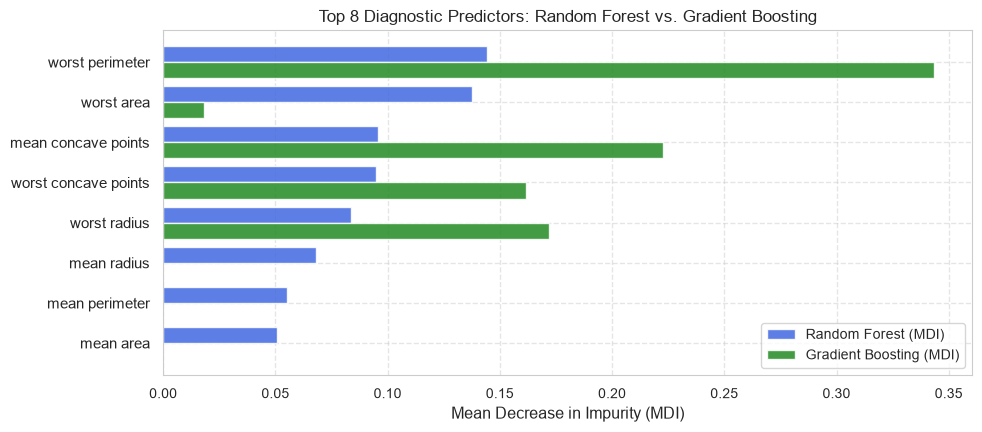

In [15]:
# Compare top 8 feature importances (MDI, shares of the total impurity decrease) of Random Forest and Gradient Boosting
m_rf = models["Random Forest (300)"]
m_gb = gb_search.best_estimator_

top_idx = np.argsort(m_rf.feature_importances_)[::-1][:8]
top_features = cancer.feature_names[top_idx]

hp.plot_feature_importances(
    top_features,
    {
        "Random Forest (MDI)": m_rf.feature_importances_[top_idx],
        "Gradient Boosting (MDI)": m_gb.feature_importances_[top_idx],
    },
    title="Top 8 Diagnostic Predictors: Random Forest vs. Gradient Boosting",
)

## 6. Experiment Tracking with Weights & Biases (W&B)

- As mandated by the course grading modalities ([`modalities.md`](https://github.com/konstantin-schekotihin/dl_course/blob/master/AI-ML/modalities.md), Section 6):
  - All student project teams must document model iteration progress and hyperparameter sweeps in **Weights & Biases**.
  - W&B ensures reproducible science, automatic metric tracking, and defensible comparison tables.
- Standard W&B Experiment Tracking Workflow:
  1. **Initialize Run**: `wandb.init(project="project-name", config=hyperparameters)`.
  2. **Log Metrics**: `wandb.log({"accuracy": acc, "f1_score": f1, "roc_auc": auc})`.
  3. **Log Diagnostic Visualizations**: `wandb.log({"roc_curve": wandb.plot.roc_curve(...)})`.
  4. **Close Run**: `wandb.finish()` (or use `with wandb.init(...) as run:`).

> ⚠️ **Important:** Log the CV scores of every configuration you try; the test set is evaluated once, for the configuration chosen by CV.

In [16]:
# W&B: one run per configuration of the gradient-boosting grid, logging its CV scores (disabled without credentials)
netrc_path = os.path.expanduser("~/.netrc")
if not (os.environ.get("WANDB_API_KEY") or os.path.exists(netrc_path)):
    os.environ["WANDB_MODE"] = "disabled"

cv_results = pd.DataFrame(gb_search.cv_results_)
for _, row in cv_results.iterrows():
    with wandb.init(project="ensemble-benchmark", config=row["params"]) as run:
        run.summary["cv_f1_mean"] = row["mean_test_score"]
        run.summary["cv_f1_std"] = row["std_test_score"]

print(cv_results[["param_n_estimators", "param_max_depth", "mean_test_score", "std_test_score", "rank_test_score"]]
      .sort_values("rank_test_score").head(5).round(3).to_string(index=False))

 param_n_estimators  param_max_depth  mean_test_score  std_test_score  rank_test_score
                400                1            0.958           0.027                1
                400                3            0.949           0.008                2
                200                1            0.948           0.019                3
                100                1            0.945           0.012                4
                200                2            0.939           0.011                5


## 7. Algorithm Selection Card: Tree Ensembles

| Dimension | Bagging | Random Forests | Gradient Boosted Trees (Boosting) |
| :--- | :--- | :--- | :--- |
| **Core Mechanism** | Deep trees on bootstrap samples, all $D$ features at each split; averaging **reduces variance**. | Bagging plus a random subset of $m$ features at each split: decorrelated trees, **lower variance**. | Sequential small trees on the original data, each fitted to the residuals of the previous ones: **reduces bias**. |
| **Best Suited For** | A simple variance reduction for unstable models. | Robust, general-purpose tabular classification & regression with little tuning. | Top predictive accuracy on tabular problems, with careful tuning. |
| **Key Hyperparameters** | • `n_estimators` $B$: more trees never overfit; the error levels off. | • `n_estimators`: more trees never overfit.<br>• `max_features` $m$ (default $\sqrt{D}$). | • `learning_rate` $\eta$.<br>• `n_estimators` $M$: can overfit, choose by CV.<br>• `max_depth`: stumps to depth $\approx 3$. |
| **Interpretability** | Variable importance only. | Variable importance only. | Variable importance only. |
| **Computational Scaling** | Parallel across trees. | Fast and embarrassingly parallelizable across all CPU cores. | Sequential; can be slower to train, though optimized engines (HistGradientBoosting, XGBoost, LightGBM) accelerate computation. |
| **Critical Failure Modes** | Correlated trees limit the variance reduction. | Cannot extrapolate continuous values outside the range observed during training; high memory footprint for large ensembles. | Overfits if $M$ or $\eta$ are too large or untuned; sensitive to label noise. |

> 💡 **Key Takeaway:** Tree ensembles are a strong default for tabular data. Use **Random Forests** for fast, reliable baselines with OOB validation; use **Gradient Boosting** when squeezing out peak predictive performance, with $M$, $\eta$ and $d$ chosen by cross-validation.